# Shipping Voyage Monte Carlo

What is the probability that a westbound Asia-Northern Europe container vayage produces a negative voyage result?

## 1. Setup

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

## 2. Load data

In [ ]:
brent_url = "https://github.com/Isakstevik/shipping-route-monte-carlo-V1/raw/refs/heads/main/data/processed/brent_monthly_processed.csv"

brent_df = pd.read_csv(brent_url)
brent_df.head()

,observation_date,MCOILBRENTEU,monthly_return
0,2019-01-01,59.41,NaN
1,2019-02-01,63.96,0.076586
2,2019-03-01,66.14,0.034084
3,2019-04-01,71.23,0.076958
4,2019-05-01,71.32,0.001264


In [ ]:
wci_url = "https://github.com/Isakstevik/shipping-route-monte-carlo-V1/raw/refs/heads/main/data/processed/wci_shanghai_rotterdam_processed.csv"

wci_df = pd.read_csv(wci_url)
freight_rates = wci_df["freight_rate"].to_numpy()

print(f'Number of months:  {len(freight_rates)}')
print(f'Mean:              ${freight_rates.mean():,.0f}')
print(f'Median:            ${np.median(freight_rates):,.0f}')
print(f'Min:               ${freight_rates.min():,.0f}')
print(f'Max:               ${freight_rates.max():,.0f}')



Number of months:  62
Mean:              $5,216
Median:            $3,522
Min:               $1,027
Max:               $14,807


In [ ]:
brent_df["month"] = pd.to_datetime(brent_df["observation_date"]).dt.strftime("%Y-%m")

paired_df = pd.merge(wci_df, brent_df[["month", "MCOILBRENTEU"]], on="month", how="inner")

print(f"Paired months:  {len(paired_df)}")
paired_df.head()

Paired months:  62


,month,assessment_date,freight_rate,MCOILBRENTEU
0,2021-07,2021-07-01,12203,75.17
1,2021-08,2021-08-05,13628,70.75
2,2021-09,2021-09-02,14074,74.49
3,2021-10,2021-10-07,14807,83.54
4,2021-11,2021-11-04,13801,81.05


In [ ]:
brent_latest = brent_df["MCOILBRENTEU"].iloc[-1]
print(f"Latest Brent:  ${brent_latest:.2f} ({brent_df['observation_date'].iloc[-1]})")

paired_df[["freight_rate", "MCOILBRENTEU"]].corr()

Latest Brent:  $91.08 (2026-08-01)


,freight_rate,MCOILBRENTEU
freight_rate,1.000000,0.288071
MCOILBRENTEU,0.288071,1.000000


## 3. Inputs

In [ ]:
# - Revenue
freight_rate = 4500               # USD per FEU
capacity_teu = 9012               # TEU, NYK Venus (IMO 9312793), FE1 Asia-North Europe, no scrubber (VLSFO)
utilization = 0.85                # average westbound utilization (share)
weak_market_threshold = np.median(paired_df["freight_rate"])  # USD/FEU, median of full freight sample

# - Time
sea_days = 30                     # days at sea, derived: ~10,500 nm at ~14.5 kn (implied by ONE FE1 pro forma, Laem Chabang-Rotterdam 31 days via Suez)
port_days = 5                     # days in port across 4 calls (placeholder, ~1-1.5 days per call). Sensitivity swing ~2 pp

# - Fuel
fuel_consumption_sea = 75.1       # t/day, NYK Venus MRV 2025 (total fuel / days at sea)
fuel_consumption_port = 5         # tonnes per day in port
vlsfo_baseline = 822              # USD/mt, Singapore VLSFO monthly average Aug 2026 (Ship & Bunker), same month as brent_latest
fuel_price = vlsfo_baseline       # deterministic baseline uses the same value
co2_factor = 3.114                # t CO2 per t fuel (IMO factor)
eua_price_usd = 96                # USD/t CO2, EUA Aug 2026 avg €82.3 converted at ~1.164
ets_coverage = 0.5                # voyages into the EU from a non-EU port: 50% of emissions count
ets_leg_share = 0.8               # share of sea days on the Tanjung Pelepas -> Rotterdam leg (estimate)
fueleu_deficit_share = 0.026      # VLSFO GHG intensity ~2.6% above 2025-29 FuelEU limit
fueleu_penalty_usd = 2794         # USD per t VLSFO-equivalent (EUR 2,400 x 1.164). Upper bound, pooling is cheaper

# - Other costs
charter_rate = 76_500             # USD/day, 1-yr TC 8.5k TEU non-eco, MSI Dec 2025. 2026 market ~8% firmer (Harpex), so likely conservative
suez_cost = 500_000               # USD/transit, est. for ~9k TEU incl. 12% surcharge from Jul 2026 (range 400-600k)
war_risk_cost = 250_000           # USD/transit: est. hull value $50m x 0.5% Red Sea AWRP (range 0.2-1.0%, 3% reported for some transits)
equipment_cost_per_feu = 200      # USD/FEU: container lease $50 + empty repositioning $150 (synthetic, range 100-350)
handling_cost_per_feu = 0         # USD/FEU. WCI excludes origin THC on Asia-Europe (billed separately to shipper, offsets terminal cost)

port_cost_shanghai = 30_000       # USD/call, vessel port dues (placeholder). Cargo handling excluded: THC billed separately
port_cost_yantian = 30_000        # USD/call (placeholder)
port_cost_tanjungpelepas = 30_000 # USD/call (placeholder)
port_cost_rotterdam = 30_000      # USD/call (placeholder)
# Port costs kept as placeholders: sensitivity analysis shows tripling them moves P(loss) by ~1 pp
total_port_cost = (port_cost_shanghai + port_cost_yantian
                   + port_cost_tanjungpelepas + port_cost_rotterdam)


n_simulations = 100_000

utilization_min = 0.70
utilization_mode = 0.85
utilization_max = 0.98

delay_min = 0      # days
delay_mode = 1
delay_max = 7

sea_days_cape = 40                   # Cape of Good Hope routing adds ~10 sea days (UNCTAD)
ets_leg_share_cape = 0.84            # Tanjung Pelepas -> Rotterdam share of a longer Cape voyage (estimate)

util_weak_min = 0.60                 # weak-market utilization distribution (overcapacity, e.g. 2023)
util_weak_mode = 0.75
util_weak_max = 0.90

## 4. Deterministic baseline

In [ ]:
# - Cargo
loaded_teu = capacity_teu * utilization
loaded_feu = loaded_teu / 2

# - Revenue
revenue = freight_rate * loaded_feu

# - Time
total_days = sea_days + port_days

# - Fuel
fuel_sea = fuel_consumption_sea * sea_days         # tonnes
fuel_port = fuel_consumption_port * port_days      # tonnes
fuel_cost = (fuel_sea + fuel_port) * fuel_price    # USD
ets_cost = fuel_sea * ets_leg_share * co2_factor * ets_coverage * eua_price_usd
fueleu_cost = fuel_consumption_sea * sea_days * ets_leg_share * ets_coverage * fueleu_deficit_share * fueleu_penalty_usd

# - Other costs
charter_cost = charter_rate * total_days
equipment_cost = loaded_feu * equipment_cost_per_feu
handling_cost = loaded_feu * handling_cost_per_feu

# - result
total_cost = (fuel_cost + charter_cost + total_port_cost + suez_cost + ets_cost + equipment_cost + fueleu_cost + handling_cost + war_risk_cost)
voyage_result = revenue - total_cost

In [ ]:
print(f'Revenue:          ${revenue:,.0f}')
print(f'Fuel cost:        ${fuel_cost:,.0f}')
print(f'ETS cost:         ${ets_cost:,.0f}')
print(f'Charter cost:     ${charter_cost:,.0f}')
print(f'Port cost:        ${total_port_cost:,.0f}')
print(f'Suez cost:        ${suez_cost:,.0f}')
print(f'War risk cost:    ${war_risk_cost:,.0f}')
print(f'Equipment cost:   ${equipment_cost:,.0f}')
print(f'FuelEU cost:      ${fueleu_cost:,.0f}')
print(f'Handling cost:    ${handling_cost:,.0f}')
print(f'Total cost:       ${total_cost:,.0f}')
print(f'voyage_result:    ${voyage_result:,.0f}')
print("-"*29)
print(f'Margin:           {voyage_result / revenue:.1%}')


Revenue:          $17,235,450
Fuel cost:        $1,872,516
ETS cost:         $269,408
Charter cost:     $2,677,500
Port cost:        $120,000
Suez cost:        $500,000
War risk cost:    $250,000
Equipment cost:   $766,020
FuelEU cost:      $65,467
Handling cost:    $0
Total cost:       $6,520,911
voyage_result:    $10,714,539
-----------------------------
Margin:           62.2%


## 5. Model

In [ ]:
def calculate_voyage_result(freight_rate, fuel_price, utilization, sea_days, port_days):
    loaded_feu = capacity_teu * utilization / 2
    revenue = freight_rate * loaded_feu

    total_days = sea_days + port_days

    fuel_tonnes = fuel_consumption_sea * sea_days + fuel_consumption_port * port_days
    fuel_cost = fuel_tonnes * fuel_price

    eu_leg_fuel = fuel_consumption_sea * sea_days * ets_leg_share
    ets_cost = eu_leg_fuel * co2_factor * ets_coverage * eua_price_usd
    fueleu_cost = eu_leg_fuel * ets_coverage * fueleu_deficit_share * fueleu_penalty_usd

    charter_cost = charter_rate * total_days
    equipment_cost = loaded_feu * equipment_cost_per_feu
    handling_cost = loaded_feu * handling_cost_per_feu

    total_cost = (fuel_cost + charter_cost + total_port_cost + suez_cost
                  + ets_cost + fueleu_cost + equipment_cost + handling_cost + war_risk_cost)
    return revenue - total_cost

## 6. Simulation

In [ ]:

simulated_utilization = rng.triangular(utilization_min, utilization_mode, utilization_max, size = n_simulations)
simulated_delay = rng.triangular(delay_min, delay_mode, delay_max, size=n_simulations)

sampled_months = rng.integers(0, len(paired_df), size=n_simulations)
simulated_freight_rate = paired_df["freight_rate"].to_numpy()[sampled_months]
simulated_fuel_price = vlsfo_baseline * paired_df["MCOILBRENTEU"].to_numpy()[sampled_months] / brent_latest

results = calculate_voyage_result(
    freight_rate = simulated_freight_rate,
    fuel_price = simulated_fuel_price,
    utilization = simulated_utilization,
    sea_days = sea_days,
    port_days = port_days + simulated_delay,
)

print(f'Mean delay: {simulated_delay.mean():.2f} days')
print(f'P(loss): {(results < 0).mean():.2%}')

Mean delay: 2.66 days
P(loss): 16.59%


## 7. Results

In [ ]:
print(f'Mean results:       ${results.mean():,.0f}')
print(f'Median results:     ${np.median(results):,.0f}')
print(f'Std results:        ${results.std():,.0f}')
print(f'5th percentile:     ${np.percentile(results, 5):,.0f}')
print(f'95th percentile:    ${np.percentile(results, 95):,.0f}')
print(f'P(loss):            {(results < 0).mean():.2%}')

Mean results:       $13,272,449
Median results:     $6,544,072
Std results:        $15,956,747
5th percentile:     $-1,464,243
95th percentile:    $46,860,089
P(loss):            16.59%


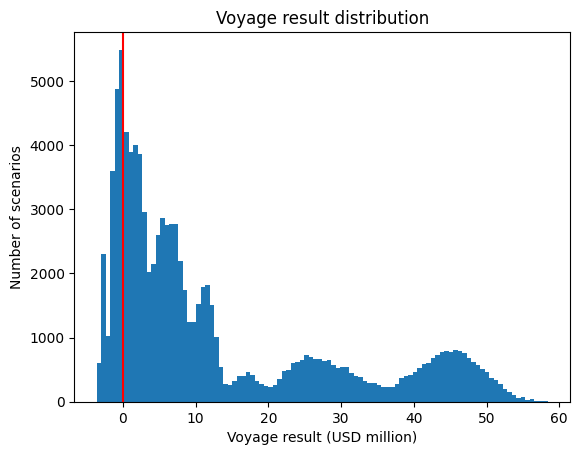

In [ ]:
plt.hist(results / 1_000_000, bins=100)
plt.axvline(0, color="red")
plt.xlabel("Voyage result (USD million)")
plt.ylabel("Number of scenarios")
plt.title("Voyage result distribution")
plt.show()

## 8. Checks

In [ ]:
independent_months = rng.integers(0, len(paired_df), size=n_simulations)
fuel_price_independent = vlsfo_baseline * paired_df["MCOILBRENTEU"].to_numpy()[independent_months] / brent_latest

results_independent = calculate_voyage_result(
    freight_rate=simulated_freight_rate,
    fuel_price=fuel_price_independent,
    utilization=simulated_utilization,
    sea_days=sea_days,
    port_days=port_days + simulated_delay,
)

print(f"P(loss) paired:      {(results < 0).mean():.2%}")
print(f"P(loss) independent: {(results_independent < 0).mean():.2%}")

P(loss) paired:      16.59%
P(loss) independent: 17.25%


In [ ]:
check = calculate_voyage_result(
    freight_rate=freight_rate,
    fuel_price=fuel_price,
    utilization=utilization,
    sea_days=sea_days,
    port_days=port_days,
)

print(f"Function: ${check:,.0f}")
print(f"Baseline: ${voyage_result:,.0f}")
print(f"Match:    {abs(check - voyage_result) < 1}")

Function: $10,714,539
Baseline: $10,714,539
Match:    True


## 9. Sensitivity analysis

In [ ]:
def p_loss():
    res = calculate_voyage_result(
        freight_rate=simulated_freight_rate,
        fuel_price=simulated_fuel_price,
        utilization=simulated_utilization,
        sea_days=sea_days,
        port_days=port_days + simulated_delay,
    )
    return (res < 0).mean()

print(f'Base P(loss):  {p_loss():.2%}')

Base P(loss):  16.59%


In [ ]:
tests = {
    "equipment_cost_per_feu": (100,350),
    "handling_cost_per_feu": (0,150),
    "charter_rate": (65_000, 90_500),
    "suez_cost": (400_000, 600_000),
    "fuel_consumption_sea": (65, 86),
    "sea_days": (28, 33),
    "port_days": (4, 7),
    "total_port_cost": (80000, 240_000),
    "eua_price_usd": (70, 110),
    "ets_leg_share": (0.7, 0.9),
    "war_risk_cost": (100_000, 500_000),
}

rows = []
for name, (low, high) in tests.items():
    base_value = globals()[name]

    globals()[name] = low
    p_low = p_loss()

    globals()[name] = high
    p_high = p_loss()

    globals()[name] = base_value #reset

    rows.append({
        "input": name,
        "p_loss_low": p_low,
        "p_loss_high": p_high,
        "swing": abs(p_high - p_low),
    })

sensitivity_df = pd.DataFrame(rows).sort_values("swing", ascending=False)
display(sensitivity_df)

,input,p_loss_low,p_loss_high,swing
2,charter_rate,0.12654,0.20443,0.07789
0,equipment_cost_per_feu,0.13159,0.20710,0.07551
5,sea_days,0.14036,0.19838,0.05802
4,fuel_consumption_sea,0.14261,0.18889,0.04628
1,handling_cost_per_feu,0.16586,0.20710,0.04124
10,war_risk_cost,0.15248,0.18603,0.03355
6,port_days,0.15901,0.17900,0.01999
3,suez_cost,0.15719,0.17417,0.01698
7,total_port_cost,0.16242,0.17581,0.01339
8,eua_price_usd,0.15968,0.16929,0.00961


In [ ]:
print(f"Base P(loss) after loop:  {p_loss():.2%}")

Base P(loss) after loop:  16.59%


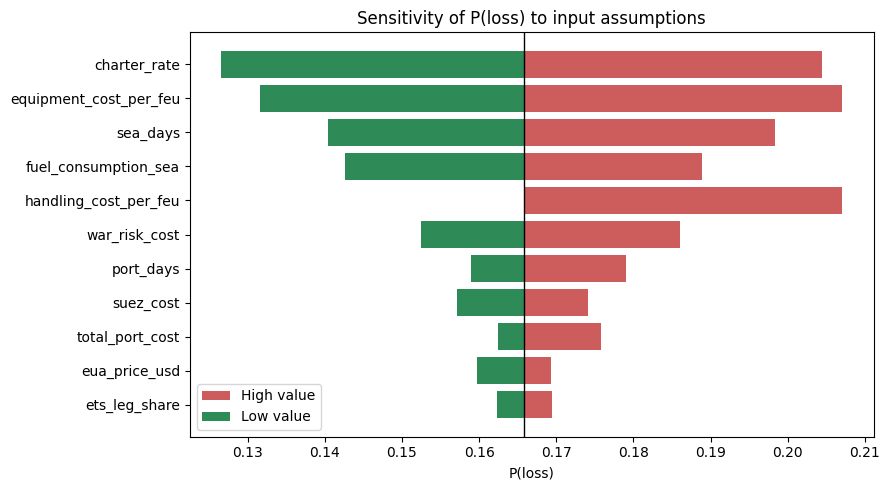

In [ ]:
plot_df = sensitivity_df.sort_values("swing")
base_p = p_loss()

plt.figure(figsize=(9, 5))
plt.barh(plot_df["input"], plot_df["p_loss_high"] - base_p, left=base_p, color="indianred", label="High value")
plt.barh(plot_df["input"], plot_df["p_loss_low"] - base_p, left=base_p, color="seagreen", label="Low value")
plt.axvline(base_p, color="black", linewidth=1)
plt.xlabel("P(loss)")
plt.title("Sensitivity of P(loss) to input assumptions")
plt.legend()
plt.tight_layout()
plt.show()

## 10. Scenarios

In [ ]:
def run_scenario(data, seed=42, linked_utilization=False):
    rng_s = np.random.default_rng(seed)

    util = rng_s.triangular(utilization_min, utilization_mode, utilization_max, size=n_simulations)
    delay = rng_s.triangular(delay_min, delay_mode, delay_max, size=n_simulations)

    months = rng_s.integers(0, len(data), size=n_simulations)
    freight = data["freight_rate"].to_numpy()[months]
    fuel = vlsfo_baseline * data["MCOILBRENTEU"].to_numpy()[months] / brent_latest

    if linked_utilization:
        util_weak = rng_s.triangular(util_weak_min, util_weak_mode, util_weak_max, size=n_simulations)
        util = np.where(freight < weak_market_threshold, util_weak, util)

    return calculate_voyage_result(
        freight_rate=freight,
        fuel_price=fuel,
        utilization=util,
        sea_days=sea_days,
        port_days=port_days + delay,
    )

In [ ]:
post_covid_df = paired_df[paired_df["month"] >= "2022-09"]
print(f"Months in post-COVID sample:  {len(post_covid_df)}")

scenarios = {
    "Full sample (Jul 2021 - Aug 2026)": paired_df,
    "Post-COVID (Sep 2022 - Aug 2026)": post_covid_df,
}

rows = []
for name, data in scenarios.items():
    res = run_scenario(data)
    rows.append({
        "scenario": name,
        "P(loss)": (res < 0).mean(),
        "median": np.median(res),
        "5th pct": np.percentile(res, 5),
        "95th pct": np.percentile(res, 95),
    })

scenario_df = pd.DataFrame(rows)
display(scenario_df.style.format({
    "P(loss)": "{:.2%}",
    "median": "${:,.0f}",
    "5th pct": "${:,.0f}",
    "95th pct": "${:,.0f}",
}))

Months in post-COVID sample:  48


,scenario,P(loss),median,5th pct,95th pct
0,Full sample (Jul 2021 - Aug 2026),16.59%,"$6,544,072","$-1,464,243","$46,860,089"
1,Post-COVID (Sep 2022 - Aug 2026),21.85%,"$3,794,506","$-1,719,987","$21,633,865"


In [ ]:
routes = {
    "Suez": {"sea_days": sea_days, "suez_cost": suez_cost, "war_risk_cost": war_risk_cost, "ets_leg_share": ets_leg_share},
    "Cape": {"sea_days": sea_days_cape, "suez_cost": 0, "war_risk_cost": 0, "ets_leg_share": ets_leg_share_cape}
}

rows = []
for route_name, params in routes.items():
    originals = {name: globals()[name] for name in params}

    for name, value in params.items():
        globals()[name] = value

    for sample_name, data in scenarios.items():
        res = run_scenario(data)
        rows.append({
            "route": route_name,
            "sample": sample_name,
            "P(loss)": (res < 0).mean(),
            "median": np.median(res),
            "5th pct": np.percentile(res, 5),
        })

    for name, value in originals.items():
        globals()[name] = value #reset

route_df = pd.DataFrame(rows)

display(route_df.style.format({
    "P(loss)": "{:.2%}",
    "median": "${:,.0f}",
    "5th pct": "${:,.0f}",
}))
print(f"Base P(loss) after routes: {p_loss():.2%}")

,route,sample,P(loss),median,5th pct
0,Suez,Full sample (Jul 2021 - Aug 2026),16.59%,"$6,544,072","$-1,464,243"
1,Suez,Post-COVID (Sep 2022 - Aug 2026),21.85%,"$3,794,506","$-1,719,987"
2,Cape,Full sample (Jul 2021 - Aug 2026),21.84%,"$5,863,208","$-2,181,335"
3,Cape,Post-COVID (Sep 2022 - Aug 2026),28.44%,"$3,145,662","$-2,433,328"


Base P(loss) after routes: 16.59%


In [ ]:
dist_tests = {
    "Utilization weak": {"utilization_min": util_weak_min, "utilization_mode": util_weak_mode, "utilization_max": util_weak_max},
    "Utilization strong (0.80/0.90/0.98)": {"utilization_min": 0.80, "utilization_mode": 0.90, "utilization_max": 0.98},
    "Delay low (0/0.5/3)": {"delay_min": 0, "delay_mode": 0.5, "delay_max": 3},
    "Delay high (0/2/14)": {"delay_min": 0, "delay_mode": 2, "delay_max": 14}
}

rows = [{"test": "Base", "P(loss)": (run_scenario(paired_df) < 0).mean()}]

for test_name, params in dist_tests.items():
    originals = {name: globals()[name] for name in params}

    for name, value in params.items():
        globals()[name] = value

    res = run_scenario(paired_df)
    rows.append({"test": test_name, "P(loss)": (res < 0).mean()})

    for name, value in originals.items():
        globals()[name] = value #reset

dist_df = pd.DataFrame(rows)
dist_df["change"] = dist_df["P(loss)"] - dist_df.loc[0, "P(loss)"]

display(dist_df.style.format({"P(loss)": "{:.2%}", "change": "{:+.2%}"}))
print(f'Base P(loss) after distribution tests: {p_loss():.2%}')

,test,P(loss),change
0,Base,16.59%,+0.00%
1,Utilization weak,21.84%,+5.26%
2,Utilization strong (0.80/0.90/0.98),13.67%,-2.91%
3,Delay low (0/0.5/3),15.56%,-1.03%
4,Delay high (0/2/14),18.19%,+1.61%


Base P(loss) after distribution tests: 16.59%


In [ ]:
rows = []
for sample_name, data in scenarios.items():
    for linked in [False, True]:
        res = run_scenario(data, linked_utilization=linked)
        rows.append({
            "sample": sample_name,
            "utilization": "Linked to freight" if linked else "Independent",
            "P(loss)": (res < 0).mean(),
            "median": np.median(res),
            "5th pct": np.percentile(res, 5),
        })

linked_df = pd.DataFrame(rows)
display(linked_df.style.format({
    "P(loss)": "{:.2%}",
    "median": "${:,.0f}",
    "5th pct": "${:,.0f}",
}))

,sample,utilization,P(loss),median,5th pct
0,Full sample (Jul 2021 - Aug 2026),Independent,16.59%,"$6,544,072","$-1,464,243"
1,Full sample (Jul 2021 - Aug 2026),Linked to freight,21.86%,"$5,962,719","$-1,972,081"
2,Post-COVID (Sep 2022 - Aug 2026),Independent,21.85%,"$3,794,506","$-1,719,987"
3,Post-COVID (Sep 2022 - Aug 2026),Linked to freight,28.51%,"$2,707,086","$-2,238,681"
